# Credit Risk Model for a Micro and MSME Loan Portfolio
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aldo02032004/msme-credit-risk-model/blob/main/msme_credit_risk_model.ipynb)

**Credit risk portfolio · Python · PD, EL, PSAK 71, Vasicek, stress test · public data**

**Summary.** This notebook builds an end-to-end credit risk model: a probability of default (PD) scorecard, bank-style validation, expected loss and PSAK 71 staging, a Monte Carlo portfolio loss distribution with a single-factor (Vasicek) model, and a macro stress test against loan loss reserves (CKPN).

**Questions answered**
1. How well does the PD model rank and calibrate risk, and is it stable?
2. What is the expected loss and the PSAK 71 reserve per segment?
3. How large can a bad year's loss be (VaR 99%, CVaR 99%)?
4. Do reserves cover losses when interest rates rise, the rupiah weakens or growth slows?
5. Which policy reduces the risk the most?

| Section | Step | Content |
|---|---|---|
| 0 | Setup | Assumptions, segment table, helpers |
| 1 | Data | Loan data (Give Me Some Credit), macro data (FRED) |
| 2 | PD model and validation | Logistic regression vs gradient boosting, AUC, KS, calibration, PSI |
| 3 | Expected loss | EL = PD × LGD × EAD, PSAK 71 stages 1-2-3 |
| 4 | Portfolio loss | Monte Carlo, 10,000 scenarios, Vasicek one-factor model |
| 5 | Stress test and policy | Macro scenarios vs reserves, KRI, score cutoff |
| 6 | **Results** | **All key tables and charts in one place** |

Sections 0-5 only compute. To see the results, go straight to **section 6**.

**Note:** the portfolio is **simulated**. Borrowers come from a public US consumer loan dataset; only the segment weights come from BRI's published financial report (Q3 2026). LGD, EAD, staging rules and macro sensitivities are explicit assumptions in section 0. This is a learning project, not a model of any real bank.

## 0. Setup

All assumptions live in the `P` dictionary and the `seg` table, so every number in the notebook can be traced back to one cell.

| Term | Meaning |
|---|---|
| PD | Probability of default within 12 months |
| LGD | Loss given default, the share of exposure lost after recovery |
| EAD | Exposure at default, outstanding plus the expected drawdown of unused limits (CCF) |
| EL | Expected loss = PD × LGD × EAD |
| ECL / CKPN | PSAK 71 expected credit loss, booked as loan loss reserves |
| VaR 99 / CVaR 99 | Loss exceeded in 1% of scenarios / average loss in those worst 1% |
| PSI | Population Stability Index, how much the score distribution has shifted |
| KRI | Key risk indicator with a green / yellow / red status |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve

sns.set_theme(style="whitegrid", font_scale=0.9)
pd.options.display.float_format = "{:,.3f}".format

P = dict(
    portfolio=10.0,                       # total outstanding portofolio simulasi, Rp triliun
    sicr_pd=0.10,                         # PD 12 bulan ≥ 10% = kenaikan risiko signifikan (Stage 2)
    margin=0.08,                          # margin bersih tahunan setelah dana & opex, untuk cutoff break-even
    pdo=20, base_score=600, base_odds=50, # skala skor: 600 poin = odds baik:buruk 50:1, +20 poin = odds 2×
    w=dict(bunga=0.3, inflasi=0.2, kurs=0.2, pdb=0.3),   # bobot makro ke faktor sistemik Z (asumsi)
    n_sims=10_000, conf=0.99, q_stress=0.99, test_size=0.3, seed=42, macro_start="2004-01-01",
)

# Bobot segmen dari laporan keuangan publikasi BRI Q3 2026 (kredit, Rp triliun).
# Hanya bobotnya yang dipakai; LGD, CCF, tenor = asumsi portofolio simulasi.
seg = pd.DataFrame([
    # segmen,            BRI,   LGD,  undrawn, CCF,  tenor, kurva rho Basel
    ("Mikro",            707.5, 0.50, 0.00,    0.00, 2,     "retail"),
    ("Kecil & Menengah", 218.6, 0.45, 0.10,    0.50, 3,     "korporasi"),
    ("Konsumer",         242.9, 0.40, 0.05,    0.75, 5,     "retail"),
    ("Komersial",         80.7, 0.40, 0.15,    0.50, 3,     "korporasi"),
    ("Korporasi",        397.5, 0.35, 0.20,    0.50, 4,     "korporasi"),
], columns=["segmen", "bri", "lgd", "undrawn", "ccf", "tenor", "kurva"]).set_index("segmen")
seg["bobot"] = seg.bri / seg.bri.sum()

# --- Helper yang dipakai di banyak sel (pola sama dengan proyek LNG) ---
idn = lambda s: s.translate(str.maketrans(",.", ".,"))              # 1,234.5 → 1.234,5
rp = lambda x: idn(f"Rp {x * 1e3:,.1f} M")                          # Rp triliun → "Rp 312,4 M" (miliar)
pct = lambda x: idn(f"{x:.1%}")
status = lambda x, hijau, kuning: np.select([x <= hijau, x <= kuning], ["HIJAU", "KUNING"], "MERAH")
tindakan = {"HIJAU": "Diterima, pantau rutin", "KUNING": "Pantau ketat, siapkan mitigasi", "MERAH": "Wajib mitigasi segera"}
warna = {"HIJAU": "#a5d6a7", "KUNING": "#ffe082", "MERAH": "#ef9a9a"}
display(seg)

,bri,lgd,undrawn,ccf,tenor,kurva,bobot
segmen,,,,,,,
Mikro,707.500,0.500,0.000,0.000,2,retail,0.430
Kecil & Menengah,218.600,0.450,0.100,0.500,3,korporasi,0.133
Konsumer,242.900,0.400,0.050,0.750,5,retail,0.147
Komersial,80.700,0.400,0.150,0.500,3,korporasi,0.049
Korporasi,397.500,0.350,0.200,0.500,4,korporasi,0.241


## 1. Data

**Loans.** [Give Me Some Credit](https://www.openml.org/d/46929) (150,000 borrowers, 10 features, target = serious delinquency within 2 years), downloaded from OpenML and cached by scikit-learn.

**Macro (FRED, original sources BI, BPS and IMF/OECD).** The interbank call rate is used as a monthly proxy for the BI rate, because the BI rate itself is not on FRED after 2013.

| Variable | FRED code | Frequency | Shock used |
|---|---|---|---|
| Interest rate (BI rate proxy) | `IRSTCI01IDM156N` | Monthly | 12-month change, pp |
| Consumer prices | `IDNCPIALLMINMEI` | Monthly | Inflation, % year on year |
| USD/IDR | `CCUSMA02IDM618N` | Monthly | 12-month change, % |
| Real GDP | `NGDPRSAXDCIDQ` | Quarterly | Growth, % year on year |

A copy of every macro series is saved in `data/` and used when the download fails.

In [2]:
gm = fetch_openml(data_id=46929, as_frame=True).frame
y = (gm.pop("FinancialDistressNextTwoYears") == "Yes").astype(int)
print(idn(f"{len(gm):,} peminjam, {gm.shape[1]} fitur, default rate 2 tahun {y.mean():.2%}"))

def load(name, fetch):                               # sama dengan proyek LNG: unduh, simpan, fallback ke CSV
    f = Path("data") / f"{name}.csv"
    try:
        s = fetch().dropna()
        f.parent.mkdir(exist_ok=True); s.to_csv(f)
    except Exception as e:
        print(f"{name}: unduhan gagal ({e}), pakai {f}")
        s = pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    return s

fred = lambda sid: pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd={P['macro_start']}",
                               index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
raw = {k: load(k, lambda s=sid: fred(s)) for k, sid in
       dict(bunga="IRSTCI01IDM156N", ihk="IDNCPIALLMINMEI", kurs="CCUSMA02IDM618N", pdb="NGDPRSAXDCIDQ").items()}

# Variabel guncangan 12 bulan, tiap seri dengan sejarahnya sendiri
mk = {"bunga": raw["bunga"].diff(12), "inflasi": raw["ihk"].pct_change(12) * 100,
      "kurs": raw["kurs"].pct_change(12) * 100, "pdb": raw["pdb"].pct_change(4) * 100}
mk = {k: s.dropna() for k, s in mk.items()}
arah = pd.Series({"bunga": 1, "inflasi": 1, "kurs": 1, "pdb": -1})   # +1 = naik itu buruk, -1 = turun itu buruk
for k, s in mk.items():
    print(f"{k:8s}: {len(s):3d} observasi, {s.index[0]:%b %Y} s/d {s.index[-1]:%b %Y}, terakhir {s.iloc[-1]:+.2f}")

150.000 peminjam. 10 fitur. default rate 2 tahun 6,68%
bunga   : 260 observasi, Jan 2005 s/d Aug 2026, terakhir +1.41
inflasi : 244 observasi, Jan 2005 s/d Apr 2025, terakhir +1.95
kurs    : 261 observasi, Jan 2005 s/d Sep 2026, terakhir +7.48
pdb     :  86 observasi, Jan 2005 s/d Apr 2026, terakhir +5.30


## 2. PD model and validation

- **Split:** 70% development, 30% validation, stratified on the target.
- **Champion: logistic regression.** Outliers capped at the development 99th percentile, missing values imputed with the median plus a missing flag, `log1p` transform, standardization. Coefficients are readable, which is why banks and regulators still prefer it.
- **Challenger: gradient boosting** (`HistGradientBoostingClassifier`) on raw features, with early stopping.
- **Metrics:** AUC and Gini (ranking), KS (separation of good and bad), Brier score and calibration curve (accuracy of the PD level), PSI (stability), and a per-segment backtest of predicted vs actual default rate.
- **12-month PD:** the target covers 2 years, so PD₁₂ = 1 − (1 − PD₂)^½.
- **Score:** points = 600 + 20/ln 2 × ln(odds / 50), so 600 points means good:bad odds of 50:1.

In [3]:
X_dev, X_val, y_dev, y_val = train_test_split(gm, y, test_size=P["test_size"], stratify=y, random_state=P["seed"])
cap = X_dev.quantile(0.99)                                          # batas outlier dari data development saja
logit = make_pipeline(FunctionTransformer(lambda X: X.clip(lower=0, upper=cap, axis=1)),
                      SimpleImputer(strategy="median", add_indicator=True),
                      FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=1000))
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=500, early_stopping=True, random_state=P["seed"])
models = {"Logistik": logit.fit(X_dev, y_dev), "Gradient boosting": gbm.fit(X_dev, y_dev)}
p_dev = {k: m.predict_proba(X_dev)[:, 1] for k, m in models.items()}
p_val = {k: m.predict_proba(X_val)[:, 1] for k, m in models.items()}

def validasi(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    return pd.Series({"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max(), "Brier": brier_score_loss(y, p),
                      "PD rata-rata": p.mean(), "Default rate aktual": y.mean()})

def psi(a, b, bins=10):                                             # a = acuan (development), b = pembanding
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[[0, -1]] = -np.inf, np.inf
    pa, pb = (np.clip(np.histogram(x, edges)[0] / len(x), 1e-6, None) for x in (a, b))
    return ((pa - pb) * np.log(pa / pb)).sum()

val = pd.DataFrame({k: validasi(y_val, p) for k, p in p_val.items()}).T
val["AUC dev"] = [roc_auc_score(y_dev, p_dev[k]) for k in val.index]
val["PSI dev→val"] = [psi(p_dev[k], p_val[k]) for k in val.index]

factor = P["pdo"] / np.log(2)
skor = lambda p: P["base_score"] + factor * np.log((1 - p) / p / P["base_odds"])
pd12 = lambda p2: 1 - (1 - p2) ** 0.5
coef = pd.Series(logit[-1].coef_[0], index=logit[1].get_feature_names_out(X_dev.columns)).sort_values(key=abs, ascending=False)

# Cek logika: model lebih baik dari acak, skor turun kalau PD naik, PSI dev→dev = 0
assert (val.AUC > 0.75).all() and skor(0.01) > skor(0.2) and psi(p_dev["Logistik"], p_dev["Logistik"]) < 1e-9

## 3. Expected loss and PSAK 71 staging

The validation sample becomes the simulated portfolio, so every loan has an out-of-sample PD and a known outcome.

- **Segments:** borrowers are ranked by monthly income and cut by BRI's segment weights (lowest income → Mikro, highest → Korporasi). This is a simulation device, not a claim about BRI borrowers.
- **Exposure:** each segment's outstanding = Rp 10 T × BRI weight, split equally across its loans. EAD = outstanding × (1 + undrawn share × CCF).
- **PSAK 71 stages** (rules in code are proxies, because the dataset has no current days-past-due):

| Stage | Rule | PD used for ECL |
|---|---|---|
| 3, credit-impaired | Ever 90+ days late in the last 2 years | 100% |
| 2, significant increase in credit risk | 30-89 days late, or PD₁₂ ≥ 10% | Lifetime PD = 1 − (1 − PD₁₂)^tenor |
| 1, performing | Everything else | PD₁₂ |

ECL is undiscounted, and macro forward-looking adjustment is handled in the stress test instead.

In [4]:
port = X_val.assign(pd2=p_val["Logistik"], default=y_val.to_numpy())
port["pd12"] = pd12(port.pd2)
port["skor"] = skor(port.pd2)
rank = port.MonthlyIncome.fillna(port.MonthlyIncome.median()).rank(method="first", pct=True)
port["segmen"] = pd.cut(rank, [0, *seg.bobot.cumsum()], labels=seg.index).astype(str)
port["segmen"] = port.segmen.replace("nan", seg.index[-1])          # pembulatan bobot kumulatif
s = seg.loc[port.segmen]
port["outstanding"] = P["portfolio"] * s.bobot.to_numpy() / port.segmen.map(port.segmen.value_counts())
port["ead"] = port.outstanding * (1 + s.undrawn.to_numpy() * s.ccf.to_numpy())
port["lgd"] = s.lgd.to_numpy()

late = port["NumberOfTime30-59DaysPastDueNotWorse"] + port["NumberOfTime60-89DaysPastDueNotWorse"]
port["stage"] = np.select([port.NumberOfTimes90DaysLate > 0, (late > 0) | (port.pd12 >= P["sicr_pd"])], [3, 2], 1)
pd_life = 1 - (1 - port.pd12) ** s.tenor.to_numpy()
port["pd_ecl"] = np.select([port.stage == 3, port.stage == 2], [1.0, pd_life], port.pd12)
port["ecl"] = port.pd_ecl * port.lgd * port.ead                    # CKPN PSAK 71
port["el12"] = np.where(port.stage == 3, 1.0, port.pd12) * port.lgd * port.ead   # kerugian 12 bulan

g = port.groupby("segmen", sort=False)
el = pd.DataFrame({
    "Jumlah pinjaman": g.size(), "EAD": g.ead.sum(), "PD12 rata-rata": g.pd12.mean(), "LGD": g.lgd.first(),
    "EL 12 bulan": g.el12.sum(), "CKPN PSAK 71": g.ecl.sum(),
    **{f"Stage {k} (% EAD)": port[port.stage == k].groupby("segmen").ead.sum() / g.ead.sum() for k in (1, 2, 3)},
}).loc[seg.index].fillna(0)
el.loc["Total"] = el.sum()
for c in ["PD12 rata-rata", "LGD"]:
    el.loc["Total", c] = np.average(el[c].iloc[:-1], weights=el.EAD.iloc[:-1])
for k in (1, 2, 3):
    el.loc["Total", f"Stage {k} (% EAD)"] = port[port.stage == k].ead.sum() / port.ead.sum()
el["Coverage CKPN/EAD"] = el["CKPN PSAK 71"] / el.EAD
ecl_stage = port.pivot_table(index="segmen", columns="stage", values="ecl", aggfunc="sum").loc[seg.index].fillna(0)

# Backtest per segmen: PD 2 tahun prediksi vs default rate aktual
bt = g.agg(prediksi=("pd2", "mean"), aktual=("default", "mean")).loc[seg.index]
assert np.isclose(port.outstanding.sum(), P["portfolio"]) and (port.ecl >= port.pd12 * port.lgd * port.ead - 1e-12).all()

## 4. Portfolio loss: Monte Carlo with a Vasicek one-factor model

Each borrower defaults when √ρ·Z + √(1−ρ)·ε < Φ⁻¹(PD), where Z is one systematic factor shared by the whole economy and ε is the borrower's own risk. Given Z, the default rate of a large pool is

PD(Z) = Φ( (Φ⁻¹(PD) − √ρ·Z) / √(1−ρ) )

- **Correlation ρ** follows the Basel II IRB curves: retail 3%-16% for Mikro and Konsumer, corporate 12%-24% for the other segments, lower ρ for higher PD.
- **10,000 scenarios** of Z ~ N(0, 1), the same Monte Carlo set-up as the LNG project. Loans are grouped into 20 PD buckets per segment so the simulation is a small matrix product.
- Stage 3 loans have already defaulted, so their loss LGD × EAD is added to every scenario.
- **Check:** in a one-factor model the 99% loss is exactly the loss at Z = Φ⁻¹(1%), so the simulated VaR must match that closed form.

In [5]:
def rho(pd_, kurva):                                                # korelasi aset Basel II IRB
    k, lo, hi = (35, 0.03, 0.16) if kurva == "retail" else (50, 0.12, 0.24)
    w = (1 - np.exp(-k * pd_)) / (1 - np.exp(-k))
    return lo * w + hi * (1 - w)

port["rho"] = [rho(p, seg.kurva[s_]) for p, s_ in zip(np.maximum(port.pd12, 0.0003), port.segmen)]  # PD floor Basel 0,03%
port["bucket"] = port.groupby("segmen").pd12.transform(lambda x: pd.qcut(x, 20, labels=False, duplicates="drop"))
port["lgd_ead"] = port.lgd * port.ead
port["pd_x"] = port.pd12 * port.lgd_ead                             # untuk rata-rata PD tertimbang eksposur

def buckets(book):                                                  # ringkas buku jadi ±100 bucket (segmen × PD)
    bk = book[book.stage < 3].groupby(["segmen", "bucket"]).agg(pd_x=("pd_x", "sum"), lgd_ead=("lgd_ead", "sum"),
                                                                rho=("rho", "mean")).reset_index()
    bk["pd"] = bk.pd_x / bk.lgd_ead
    s3 = book[book.stage == 3].groupby("segmen").el12.sum().reindex(seg.index, fill_value=0)
    return bk, s3

def loss_seg(z, book):                                              # kerugian 12 bulan per segmen untuk tiap nilai Z
    bk, s3 = book
    z, r = np.atleast_1d(z)[:, None], bk.rho.to_numpy()
    p = norm.cdf((norm.ppf(bk.pd.to_numpy()) - np.sqrt(r) * z) / np.sqrt(1 - r))   # PD bersyarat Vasicek
    L = pd.DataFrame(p * bk.lgd_ead.to_numpy(), columns=bk.segmen).T.groupby(level=0).sum().T
    return L.reindex(columns=seg.index, fill_value=0) + s3.to_numpy()

book = buckets(port)
rng = np.random.default_rng(P["seed"])
Z = rng.standard_normal(P["n_sims"])                                # seed sama → skenario sama untuk semua kebijakan
L_seg = loss_seg(Z, book)                                           # 10.000 skenario × 5 segmen
L = L_seg.sum(axis=1).to_numpy()

def metrics(c):
    var = np.quantile(c, P["conf"])
    return pd.Series({"EL (mean)": c.mean(), "Median": np.median(c), "Std": c.std(), "VaR 99": var,
                      "CVaR 99": c[c >= var].mean(), "UL = VaR − EL": var - c.mean(),
                      "VaR / portofolio": var / P["portfolio"]})

m = metrics(L)
tail = L >= m["VaR 99"]
kontrib = pd.DataFrame({"Porsi EAD": el.EAD.iloc[:-1] / el.EAD.iloc[:-1].sum(),
                        "Porsi EL": L_seg.mean() / L.mean(), "Porsi CVaR 99": L_seg[tail].mean() / L[tail].mean()})

# Cek: EL simulasi ≈ EL analitik, VaR simulasi ≈ rumus tertutup di Z = Φ⁻¹(1%), CVaR ≥ VaR ≥ EL
var_exact = loss_seg(norm.ppf(1 - P["conf"]), book).sum(axis=1).item()
assert abs(m["EL (mean)"] / port.el12.sum() - 1) < 0.02 and abs(m["VaR 99"] / var_exact - 1) < 0.03
assert m["CVaR 99"] >= m["VaR 99"] >= m["EL (mean)"]

## 5. Stress test and policy

**From macro to the systematic factor.** Each macro shock is turned into a z-score against its own history since 2005, signed so that positive means bad (higher rate, higher inflation, weaker rupiah, lower growth). The systematic factor is

C = − Σ wₖ · zₖ, with weights rate 0.3, inflation 0.2, FX 0.2, GDP 0.3 (an explicit assumption; a bank would estimate them by regressing its own default rates on macro data).

The composite C is mapped to the Vasicek factor by its empirical percentile: Z = Φ⁻¹(share of months since 2005 with C at least this bad). Percentiles are used instead of assuming C is normal, because macro shocks have fat tails.

**Scenarios.** Severity is taken from history, not invented. In a single-driver scenario the shocked variables are set to their worst 1% historical value (99th percentile in the bad direction) and the others stay at their latest value. The combined scenario replays the worst historical month of the composite.

| Scenario | Shocked variables |
|---|---|
| Baseline | None, latest macro values |
| Interest rate up | Rate and inflation at P99 |
| Rupiah weakens | USD/IDR at P99 |
| Growth slows | GDP at P99 (bad tail) |
| Combined | All four, as in the worst month since 2005 |

The stressed loss is the 12-month loss at that Z. It is compared with the PSAK 71 reserve (CKPN), which should cover expected loss, and with CKPN plus economic capital (UL at 99%), which should cover a bad year.

**Policy: score cutoff.** A loan is worth making when the expected margin covers the expected loss, margin × (1 − PD) ≥ PD × LGD, so the break-even PD is margin / (margin + LGD). The cutoff is applied to the simulated book as if those loans had not been originated, and checked against actual outcomes.

In [6]:
hist = pd.DataFrame(mk).resample("MS").last().ffill().loc["2005":]   # PDB kuartalan & IHK terakhir diisi maju
stat = pd.DataFrame({"terakhir": hist.iloc[-1], "mean": hist.mean(), "std": hist.std(),
                     "stres P99": [hist[k].quantile(P["q_stress"] if arah[k] > 0 else 1 - P["q_stress"]) for k in hist]})
w = pd.Series(P["w"])
komposit = lambda x: -(arah * (x - stat["mean"]) / stat["std"]) @ w # z-score bertimbang, negatif = buruk
c_hist = komposit(hist)
t_buruk = c_hist.idxmin()                                           # bulan makro historis terburuk
c_urut = np.sort(c_hist)
frek = lambda c: (np.searchsorted(c_urut, c, side="right") + 0.5) / (len(c_urut) + 1)   # persentil empiris
# ponytail: pemetaan persentil (bukan asumsi normal) karena ekor makro tebal; ganti regresi default rate bila ada data NPL bank

skenario = {"Baseline": stat.terakhir, "Suku bunga naik": ["bunga", "inflasi"], "Rupiah melemah": ["kurs"],
            "Pertumbuhan melambat": ["pdb"], f"Gabungan (historis {t_buruk:%b %Y})": hist.loc[t_buruk]}
ckpn = port.ecl.sum()
rows = []
for nama_s, x in skenario.items():
    if isinstance(x, list):                                         # guncang variabel terpilih ke P99, sisanya terakhir
        x = stat.terakhir.where(~stat.index.isin(x), stat["stres P99"])
    f_ = frek(komposit(x))
    z = norm.ppf(f_)                                                # persentil historis → faktor sistemik Z
    Ls = loss_seg(z, book).iloc[0]
    rows.append({"Skenario": nama_s, **x.to_dict(), "Z": z, "Frekuensi historis": f_,
                 "Kerugian 12 bulan": Ls.sum(), "CKPN": ckpn, "Kelebihan/(kekurangan)": ckpn - Ls.sum(),
                 "Coverage CKPN": ckpn / Ls.sum(), "Coverage CKPN + UL": (ckpn + m["UL = VaR − EL"]) / Ls.sum(),
                 **{f"Rugi {k}": v for k, v in Ls.items()}})
stres = pd.DataFrame(rows).set_index("Skenario")
gab = stres.iloc[-1]

# KRI: (nama, nilai, batas hijau, batas kuning, arah) — arah -1 = makin tinggi makin baik
hhi = (kontrib["Porsi EAD"] ** 2).sum()
s23 = port[port.stage > 1].ead.sum() / port.ead.sum()
npl = port[port.stage == 3].ead.sum() / port.ead.sum()
kri = pd.DataFrame([
    ("AUC model PD",                        val.AUC["Logistik"],     0.75, 0.70, -1),
    ("PSI skor (dev → val)",                val["PSI dev→val"]["Logistik"], 0.10, 0.25, 1),
    ("NPL proxy, Stage 3 (% EAD)",          npl,                     0.03, 0.05, 1),   # batas NPL OJK 5%
    ("Stage 2 + 3 (% EAD)",                 s23,                     0.10, 0.20, 1),
    ("Konsentrasi segmen (HHI)",            hhi,                     0.25, 0.35, 1),
    ("VaR 99 / portofolio",                 m["VaR / portofolio"],   0.06, 0.10, 1),
    ("Coverage CKPN vs stres gabungan",     gab["Coverage CKPN"],    1.00, 0.80, -1),
], columns=["KRI", "nilai", "hijau", "kuning", "arah"]).set_index("KRI")
kri["status"] = [str(status(r.arah * r.nilai, r.arah * r.hijau, r.arah * r.kuning)) for r in kri.itertuples()]
kri["tindakan"] = kri.status.map(tindakan)

# Rekomendasi: cutoff skor break-even per segmen
seg["pd_be"] = P["margin"] / (P["margin"] + seg.lgd)
seg["cutoff skor"] = skor(1 - (1 - seg.pd_be) ** 2)                 # PD12 break-even → PD 2 tahun → poin
port["lolos"] = port.pd12 <= port.segmen.map(seg.pd_be)            # pinjaman yang tetap disalurkan
lolos = port[port.lolos]
L_cut = loss_seg(Z, buckets(lolos)).sum(axis=1).to_numpy()
m_cut = metrics(L_cut)
cut = pd.DataFrame({
    "Tanpa cutoff": [1.0, port.default.mean(), port.ead.sum(), m["EL (mean)"], m["VaR 99"], m["CVaR 99"],
                     gab["Kerugian 12 bulan"], ckpn],
    "Dengan cutoff": [port.lolos.mean(), lolos.default.mean(), lolos.ead.sum(), m_cut["EL (mean)"], m_cut["VaR 99"],
                      m_cut["CVaR 99"], loss_seg(gab.Z, buckets(lolos)).sum(axis=1).item(), lolos.ecl.sum()],
}, index=["Approval rate", "Bad rate aktual 2 tahun", "EAD", "EL", "VaR 99", "CVaR 99", "Rugi stres gabungan", "CKPN"])
cut["Perubahan (%)"] = (cut["Dengan cutoff"] / cut["Tanpa cutoff"] - 1) * 100
ditolak_bad = port[~port.lolos].default.mean()                      # bad rate aktual pinjaman yang ditolak

# Cek: stres gabungan lebih buruk dari baseline, cutoff menurunkan EL dan bad rate
assert gab["Kerugian 12 bulan"] > stres.loc["Baseline", "Kerugian 12 bulan"]
assert m_cut["EL (mean)"] < m["EL (mean)"] and lolos.default.mean() < port.default.mean() < ditolak_bad

## 6. Results

### 6.1 Summary

In [7]:
ks = pd.Series({k: str(s_) for k, s_ in kri.status.items()})
print(f"RINGKASAN RISIKO KREDIT · portofolio simulasi {rp(P['portfolio'])} · " + idn(f"{len(port):,} pinjaman"))
print(f"- Model PD    : AUC {val.AUC['Logistik']:.3f}, KS {val.KS['Logistik']:.3f}, PSI {val['PSI dev→val']['Logistik']:.4f} "
      f"(gradient boosting AUC {val.AUC['Gradient boosting']:.3f})")
print(f"- EL 12 bulan : {rp(port.el12.sum())} ({pct(port.el12.sum() / port.ead.sum())} dari EAD), CKPN PSAK 71 {rp(ckpn)}")
print(f"- Portofolio  : VaR 99 {rp(m['VaR 99'])}, CVaR 99 {rp(m['CVaR 99'])}, UL {rp(m['UL = VaR − EL'])}")
print(f"- Stres       : {gab.name} {rp(gab['Kerugian 12 bulan'])} (Z {idn(f'{gab.Z:.2f}')}), "
      f"coverage CKPN {pct(gab['Coverage CKPN'])}, CKPN + UL {pct(gab['Coverage CKPN + UL'])}")
print(f"- KRI         : " + ", ".join(f"{k} {v}" for k, v in ks.value_counts().items()))
print(f"- Rekomendasi : cutoff PD break-even, approval {pct(port.lolos.mean())}, EL {cut.loc['EL', 'Perubahan (%)']:+.0f}%, "
      f"VaR 99 {cut.loc['VaR 99', 'Perubahan (%)']:+.0f}%")

RINGKASAN RISIKO KREDIT · portofolio simulasi Rp 10.000,0 M · 45.000 pinjaman
- Model PD    : AUC 0.853, KS 0.537, PSI 0.0003 (gradient boosting AUC 0.864)
- EL 12 bulan : Rp 366,2 M (3,5% dari EAD), CKPN PSAK 71 Rp 435,5 M
- Portofolio  : VaR 99 Rp 656,3 M, CVaR 99 Rp 756,9 M, UL Rp 289,2 M
- Stres       : Gabungan (historis Nov 2005) Rp 695,6 M (Z -2,53), coverage CKPN 62,6%, CKPN + UL 104,2%
- KRI         : MERAH 3, HIJAU 2, KUNING 2
- Rekomendasi : cutoff PD break-even, approval 95,3%, EL -49%, VaR 99 -29%


### 6.2 PD model validation

Champion (logistik) vs challenger (gradient boosting), sampel validasi:


,AUC,Gini,KS,Brier,PD rata-rata,Default rate aktual,AUC dev,PSI dev→val
Logistik,0.853,0.707,0.537,0.050,0.067,0.067,0.853,0.000
Gradient boosting,0.864,0.729,0.576,0.049,0.067,0.067,0.884,0.000



Koefisien regresi logistik (fitur terstandardisasi, diurutkan dari pengaruh terbesar):


,koefisien
RevolvingUtilizationOfUnsecuredLines,0.725
NumberOfTimes90DaysLate,0.342
NumberOfTime30-59DaysPastDueNotWorse,0.324
age,-0.210
NumberOfTime60-89DaysPastDueNotWorse,0.185
NumberOfOpenCreditLinesAndLoans,0.147
NumberOfDependents,0.038
NumberRealEstateLoansOrLines,0.023
missingindicator_MonthlyIncome,-0.012
missingindicator_NumberOfDependents,-0.012



Backtest per segmen, PD 2 tahun prediksi vs default rate aktual:


,prediksi,aktual,selisih
segmen,,,
Mikro,0.079,0.084,-0.005
Kecil & Menengah,0.055,0.056,-0.000
Konsumer,0.066,0.062,0.004
Komersial,0.061,0.052,0.009
Korporasi,0.055,0.049,0.006


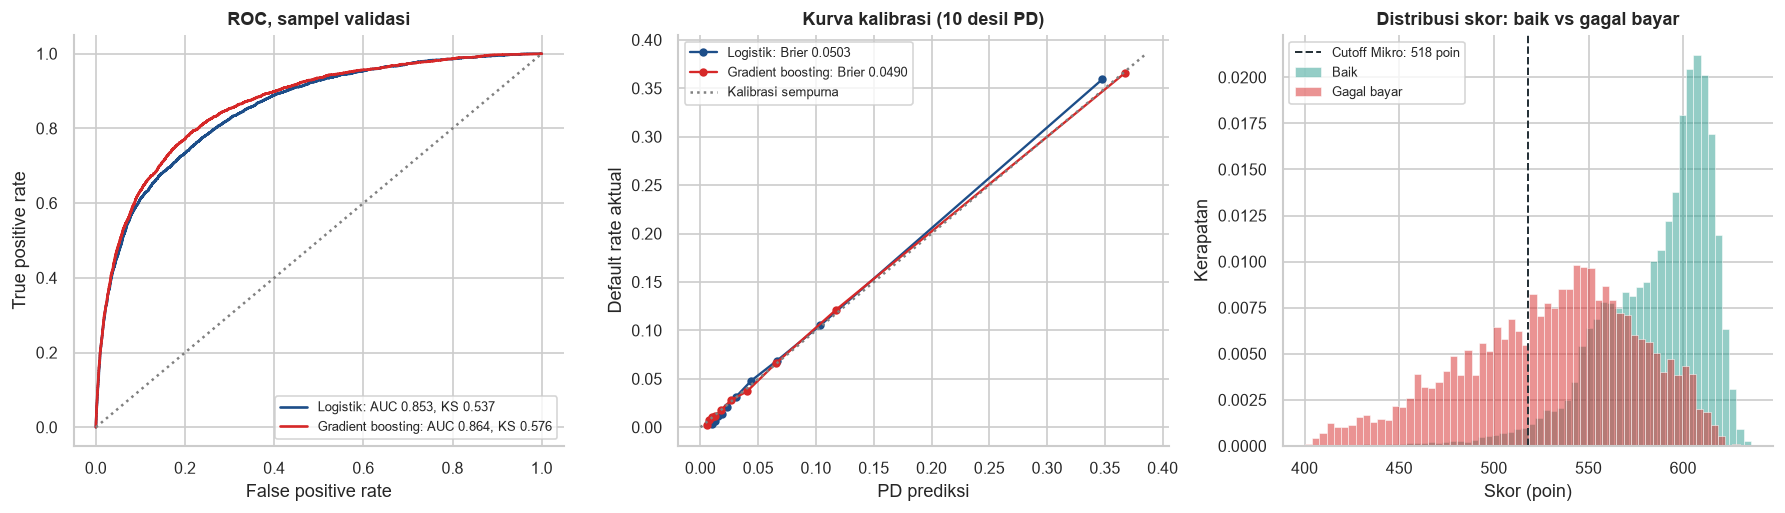

In [8]:
print("Champion (logistik) vs challenger (gradient boosting), sampel validasi:"); display(val)
print("\nKoefisien regresi logistik (fitur terstandardisasi, diurutkan dari pengaruh terbesar):")
display(coef.to_frame("koefisien"))
print("\nBacktest per segmen, PD 2 tahun prediksi vs default rate aktual:")
display(bt.assign(selisih=bt.prediksi - bt.aktual))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4), dpi=120)
for (k, p), c in zip(p_val.items(), ["#1d4e89", "#d62828"]):
    fpr, tpr, _ = roc_curve(y_val, p)
    ax[0].plot(fpr, tpr, color=c, lw=1.6, label=f"{k}: AUC {val.AUC[k]:.3f}, KS {val.KS[k]:.3f}")
    pt, pp = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax[1].plot(pp, pt, "o-", color=c, ms=4, lw=1.4, label=f"{k}: Brier {val.Brier[k]:.4f}")
ax[0].plot([0, 1], [0, 1], ":", color="grey")
ax[0].set(title="ROC, sampel validasi", xlabel="False positive rate", ylabel="True positive rate")
lim = max(ax[1].get_xlim()[1], ax[1].get_ylim()[1])
ax[1].plot([0, lim], [0, lim], ":", color="grey", label="Kalibrasi sempurna")
ax[1].set(title="Kurva kalibrasi (10 desil PD)", xlabel="PD prediksi", ylabel="Default rate aktual")
for lab, d, c in [("Baik", port[port.default == 0], "#2a9d8f"), ("Gagal bayar", port[port.default == 1], "#d62828")]:
    sns.histplot(d.skor, bins=60, stat="density", color=c, alpha=0.5, edgecolor="white", linewidth=0.3, label=lab, ax=ax[2])
ax[2].axvline(seg["cutoff skor"]["Mikro"], color="#263238", ls="--", lw=1.2,
              label=f"Cutoff Mikro: {seg['cutoff skor']['Mikro']:.0f} poin")
ax[2].set(title="Distribusi skor: baik vs gagal bayar", xlabel="Skor (poin)", ylabel="Kerapatan")
for a in ax:
    a.legend(fontsize=8, frameon=True, edgecolor="#cccccc"); a.title.set(fontweight="bold"); sns.despine(ax=a)
plt.tight_layout(); plt.savefig("images/validation.png", bbox_inches="tight"); plt.show()

### 6.3 Expected loss and PSAK 71

In [9]:
print(f"EL dan CKPN per segmen (nilai uang dalam Rp triliun, portofolio simulasi {rp(P['portfolio'])}):"); display(el)
print("\nCKPN per stage (Rp triliun):"); display(ecl_stage.rename(columns=lambda k: f"Stage {k}"))

EL dan CKPN per segmen (nilai uang dalam Rp triliun, portofolio simulasi Rp 10.000,0 M):


,Jumlah pinjaman,EAD,PD12 rata-rata,LGD,EL 12 bulan,CKPN PSAK 71,Stage 1 (% EAD),Stage 2 (% EAD),Stage 3 (% EAD),Coverage CKPN/EAD
segmen,,,,,,,,,,
Mikro,19328,4.295,0.044,0.500,0.213,0.233,0.772,0.153,0.075,0.054
Kecil & Menengah,5972,1.393,0.031,0.450,0.044,0.051,0.838,0.109,0.053,0.037
Konsumer,6636,1.530,0.037,0.400,0.046,0.065,0.792,0.155,0.052,0.043
Komersial,2204,0.527,0.033,0.400,0.014,0.017,0.805,0.152,0.043,0.033
Korporasi,10860,2.655,0.029,0.350,0.049,0.069,0.821,0.149,0.030,0.026
Total,45000,10.400,0.037,0.435,0.366,0.436,0.798,0.147,0.056,0.042



CKPN per stage (Rp triliun):


stage,Stage 1,Stage 2,Stage 3
segmen,,,
Mikro,0.030,0.043,0.161
Kecil & Menengah,0.007,0.011,0.033
Konsumer,0.008,0.025,0.032
Komersial,0.003,0.006,0.009
Korporasi,0.012,0.028,0.028


### 6.4 Portfolio loss and stress test

In [10]:
print("Distribusi kerugian 12 bulan, 10.000 skenario Vasicek (Rp triliun):"); display(m.to_frame("nilai"))
print("\nKontribusi segmen ke eksposur, EL dan CVaR 99:"); display(kontrib)
print("\nStatistik makro (guncangan 12 bulan sejak 2005) dan nilai stres P99:"); display(stat)
cols = ["bunga", "inflasi", "kurs", "pdb", "Z", "Frekuensi historis", "Kerugian 12 bulan", "CKPN",
        "Kelebihan/(kekurangan)", "Coverage CKPN", "Coverage CKPN + UL"]
print("\nStress test vs CKPN (bunga Δpp, inflasi %, kurs Δ%, pdb % yoy; uang Rp triliun):"); display(stres[cols])

Distribusi kerugian 12 bulan, 10.000 skenario Vasicek (Rp triliun):


,nilai
EL (mean),0.367
Median,0.346
Std,0.077
VaR 99,0.656
CVaR 99,0.757
UL = VaR − EL,0.289
VaR / portofolio,0.066



Kontribusi segmen ke eksposur, EL dan CVaR 99:


,Porsi EAD,Porsi EL,Porsi CVaR 99
segmen,,,
Mikro,0.413,0.582,0.476
Kecil & Menengah,0.134,0.120,0.144
Konsumer,0.147,0.126,0.117
Komersial,0.051,0.038,0.052
Korporasi,0.255,0.133,0.212



Statistik makro (guncangan 12 bulan sejak 2005) dan nilai stres P99:


,terakhir,mean,std,stres P99
bunga,1.410,-0.125,1.758,5.314
inflasi,1.945,5.010,3.417,17.419
kurs,7.480,3.382,8.063,25.887
pdb,5.299,5.002,1.912,-4.059



Stress test vs CKPN (bunga Δpp, inflasi %, kurs Δ%, pdb % yoy; uang Rp triliun):


,bunga,inflasi,kurs,pdb,Z,Frekuensi historis,Kerugian 12 bulan,CKPN,Kelebihan/(kekurangan),Coverage CKPN,Coverage CKPN + UL
Skenario,,,,,,,,,,,
Baseline,1.410,1.945,7.480,5.299,-0.336,0.368,0.366,0.436,0.069,1.189,1.978
Suku bunga naik,5.314,17.419,7.480,5.299,-2.344,0.010,0.649,0.436,-0.214,0.671,1.116
Rupiah melemah,1.410,1.945,25.887,5.299,-1.066,0.143,0.432,0.436,0.004,1.009,1.679
Pertumbuhan melambat,1.410,1.945,7.480,-4.059,-2.116,0.017,0.598,0.436,-0.162,0.729,1.213
Gabungan (historis Nov 2005),4.840,18.347,11.279,4.554,-2.529,0.006,0.696,0.436,-0.260,0.626,1.042


### 6.5 Key risk indicators and recommendation

In [11]:
with pd.option_context("display.max_colwidth", None):
    display(kri)
print("\nCutoff break-even per segmen, PD12* = margin / (margin + LGD):")
display(seg[["lgd", "pd_be", "cutoff skor"]].rename(columns={"pd_be": "PD12 break-even"}))
print("\nEfek cutoff pada portofolio simulasi:"); display(cut)
print(f"\nREKOMENDASI: terapkan cutoff skor per segmen (Mikro {seg['cutoff skor']['Mikro']:.0f} poin). "
      f"{pct(1 - port.lolos.mean())} pengajuan ditolak; bad rate aktual kelompok ini {pct(ditolak_bad)} "
      f"vs {pct(lolos.default.mean())} untuk yang lolos. EL turun {-cut.loc['EL', 'Perubahan (%)']:.0f}%, "
      f"VaR 99 turun {-cut.loc['VaR 99', 'Perubahan (%)']:.0f}%, rugi stres gabungan turun "
      f"{-cut.loc['Rugi stres gabungan', 'Perubahan (%)']:.0f}%.")

,nilai,hijau,kuning,arah,status,tindakan
KRI,,,,,,
AUC model PD,0.853,0.750,0.700,-1,HIJAU,"Diterima, pantau rutin"
PSI skor (dev → val),0.000,0.100,0.250,1,HIJAU,"Diterima, pantau rutin"
"NPL proxy, Stage 3 (% EAD)",0.056,0.030,0.050,1,MERAH,Wajib mitigasi segera
Stage 2 + 3 (% EAD),0.202,0.100,0.200,1,MERAH,Wajib mitigasi segera
Konsentrasi segmen (HHI),0.278,0.250,0.350,1,KUNING,"Pantau ketat, siapkan mitigasi"
VaR 99 / portofolio,0.066,0.060,0.100,1,KUNING,"Pantau ketat, siapkan mitigasi"
Coverage CKPN vs stres gabungan,0.626,1.000,0.800,-1,MERAH,Wajib mitigasi segera



Cutoff break-even per segmen, PD12* = margin / (margin + LGD):


,lgd,PD12 break-even,cutoff skor
segmen,,,
Mikro,0.500,0.138,517.779
Kecil & Menengah,0.450,0.151,514.503
Konsumer,0.400,0.167,510.811
Komersial,0.400,0.167,510.811
Korporasi,0.350,0.186,506.586



Efek cutoff pada portofolio simulasi:


,Tanpa cutoff,Dengan cutoff,Perubahan (%)
Approval rate,1.000,0.953,-4.727
Bad rate aktual 2 tahun,0.067,0.046,-31.433
EAD,10.400,9.916,-4.649
EL,0.367,0.188,-48.797
VaR 99,0.656,0.467,-28.779
CVaR 99,0.757,0.566,-25.173
Rugi stres gabungan,0.696,0.506,-27.258
CKPN,0.436,0.243,-44.207



REKOMENDASI: terapkan cutoff skor per segmen (Mikro 518 poin). 4,7% pengajuan ditolak; bad rate aktual kelompok ini 49,0% vs 4,6% untuk yang lolos. EL turun 49%, VaR 99 turun 29%, rugi stres gabungan turun 27%.


### 6.6 Dashboard

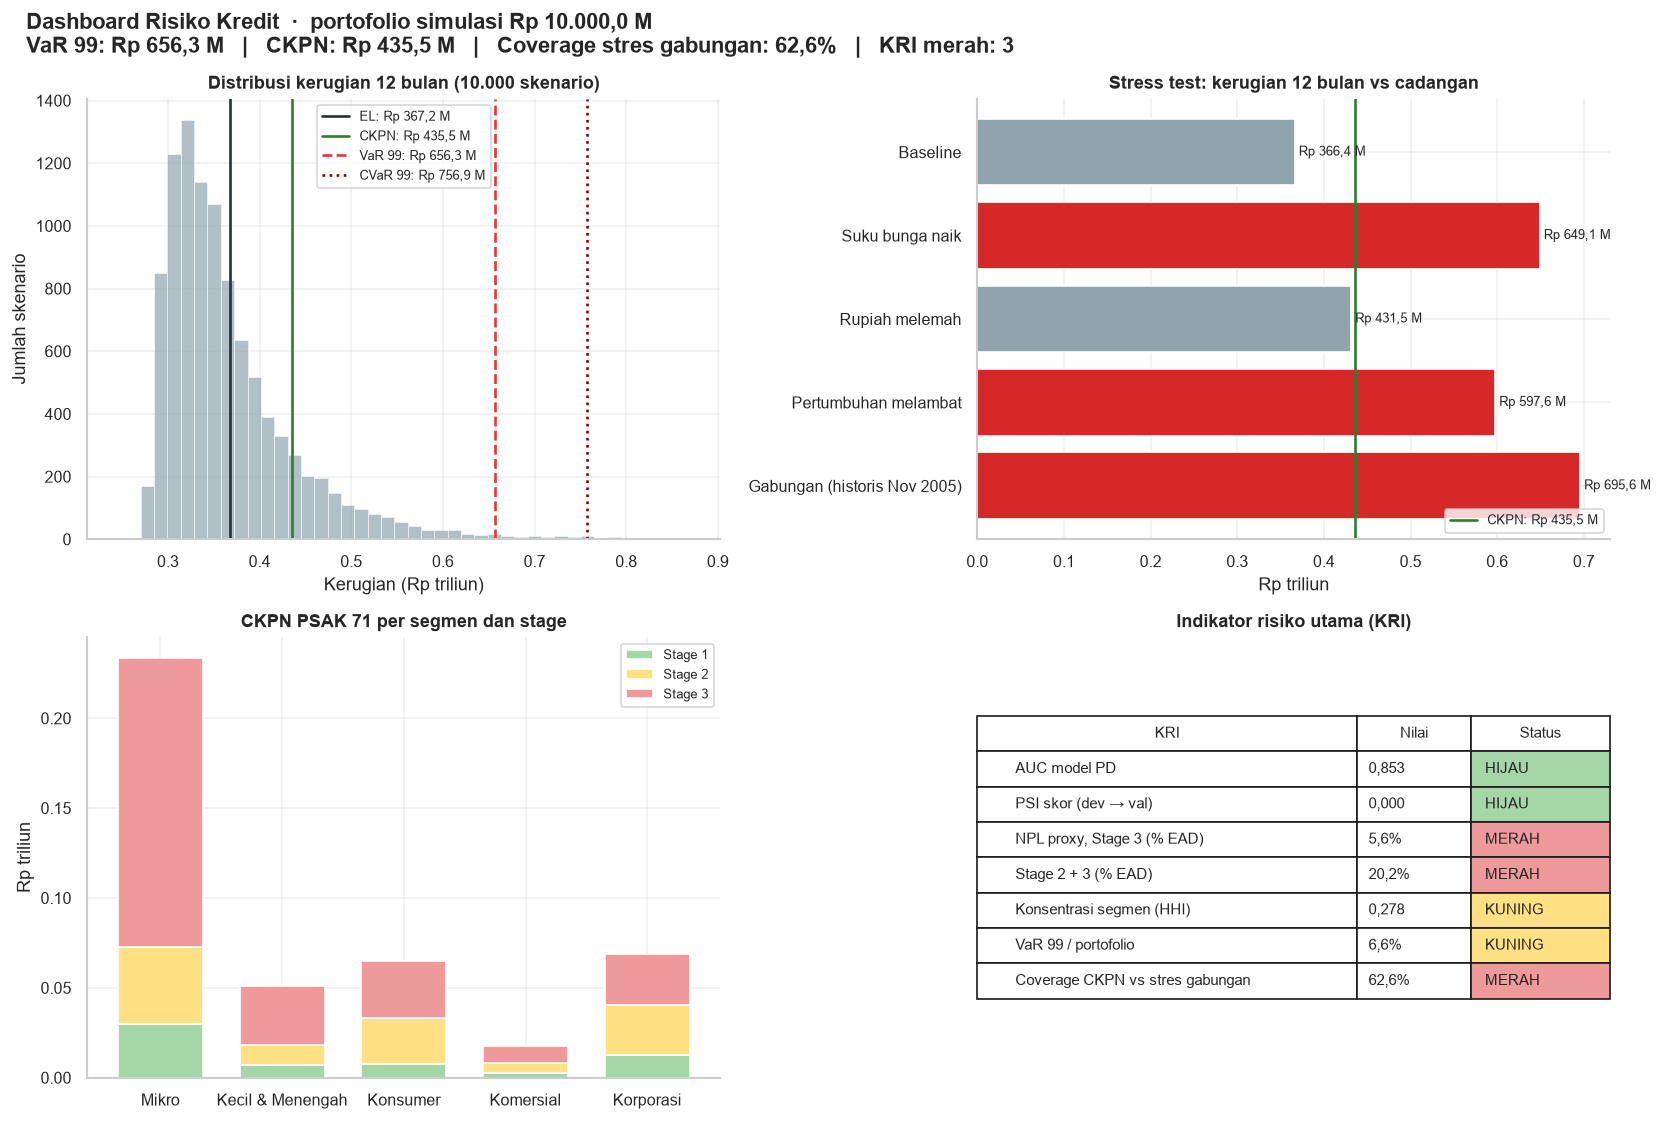

In [12]:
fig, ax = plt.subplot_mosaic([["loss", "stres"], ["seg", "kri"]], figsize=(14, 9.5), dpi=120,
                             gridspec_kw={"height_ratios": [1, 1]})
fig.suptitle(f"Dashboard Risiko Kredit  ·  portofolio simulasi {rp(P['portfolio'])}\n"
             f"VaR 99: {rp(m['VaR 99'])}   |   CKPN: {rp(ckpn)}   |   Coverage stres gabungan: {pct(gab['Coverage CKPN'])}   |   "
             f"KRI merah: {(kri.status == 'MERAH').sum()}", fontsize=13, fontweight="bold", x=0.02, ha="left")

# (a) Distribusi kerugian
sns.histplot(L, bins=80, color="#90a4ae", alpha=0.7, edgecolor="white", linewidth=0.3, ax=ax["loss"])
for v, lab, c, ls in [(m["EL (mean)"], "EL", "#263238", "-"), (ckpn, "CKPN", "#2e7d32", "-"),
                      (m["VaR 99"], "VaR 99", "#e53935", "--"), (m["CVaR 99"], "CVaR 99", "#8e0000", ":")]:
    ax["loss"].axvline(v, color=c, ls=ls, lw=1.6, label=f"{lab}: {rp(v)}")
ax["loss"].set(title="Distribusi kerugian 12 bulan (10.000 skenario)", xlabel="Kerugian (Rp triliun)", ylabel="Jumlah skenario",
               xlim=(None, np.quantile(L, 0.9995)))
ax["loss"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (b) Stress test vs CKPN
sc = stres["Kerugian 12 bulan"]
ax["stres"].barh(sc.index[::-1], sc[::-1], color=["#d62828" if v > ckpn else "#90a4ae" for v in sc[::-1]])
ax["stres"].axvline(ckpn, color="#2e7d32", lw=1.6, label=f"CKPN: {rp(ckpn)}")
for i, v in enumerate(sc[::-1]):
    ax["stres"].text(v, i, f" {rp(v)}", va="center", fontsize=8)
ax["stres"].set(title="Stress test: kerugian 12 bulan vs cadangan", xlabel="Rp triliun")
ax["stres"].legend(fontsize=8, loc="lower right", frameon=True, edgecolor="#cccccc")

# (c) CKPN per segmen dan stage
ecl_stage.rename(columns=lambda k: f"Stage {k}").plot.bar(stacked=True, color=["#a5d6a7", "#ffe082", "#ef9a9a"],
                                                          ax=ax["seg"], rot=0, width=0.7)
ax["seg"].set(title="CKPN PSAK 71 per segmen dan stage", xlabel="", ylabel="Rp triliun")
ax["seg"].legend(fontsize=8, frameon=True, edgecolor="#cccccc")

# (d) Tabel KRI berwarna
fmt = lambda k, v: pct(v) if k.endswith(("EAD)", "portofolio", "stres gabungan")) else idn(f"{v:.3f}")
t = ax["kri"].table(cellText=[[k, fmt(k, r.nilai), r.status] for k, r in kri.iterrows()],
                    colLabels=["KRI", "Nilai", "Status"], cellLoc="left", colWidths=[0.6, 0.18, 0.22], loc="center")
t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.6)
for i, r in enumerate(kri.itertuples(), start=1):
    t[i, 2].set_facecolor(warna[r.status])
ax["kri"].axis("off"); ax["kri"].set_title("Indikator risiko utama (KRI)")

for a in ax.values():
    a.title.set(fontsize=11, fontweight="bold")
    if a is not ax["kri"]:
        a.grid(alpha=0.3); sns.despine(ax=a)
plt.tight_layout(); plt.savefig("images/dashboard.png", bbox_inches="tight"); plt.show()

## Limitations

- The portfolio is simulated: US consumer borrowers mapped to Indonesian segments by income. Results describe the method, not BRI or any real bank.
- Stage rules are proxies (no current days past due in the data), and ECL is undiscounted with no forward-looking overlay.
- LGD and CCF are fixed assumptions per segment; there is no downturn LGD and no PD-LGD correlation.
- The Vasicek model uses one factor and a large-pool approximation, so single-name concentration (large corporate borrowers) is not captured.
- Macro weights wₖ are assumptions. A bank would estimate them from its own default history (for example a regression of default rates on OJK and BI data).